# Retail Demand EDA and Model Readiness Review

This notebook evaluates the engineered demand dataset for the Smart Retail forecasting system. The goal is to diagnose seasonality, zero inflation, price sensitivity, and the predictive signal in lag/rolling features before moving into the forecasting model selection phase.

The analysis is grounded in a daily item-level panel with explicit zero-demand rows, which is essential in retail because unsold days are valid business states rather than missing observations.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 140


data_paths = (
    Path("data/processed/daily_demand_features.csv"),
    Path("../data/processed/daily_demand_features.csv"),
)
data_path = next((path for path in data_paths if path.exists()), None)
if data_path is None:
    checked_paths = ", ".join(str(path) for path in data_paths)
    raise FileNotFoundError(
        f"The feature dataset is missing. Checked: {checked_paths}. "
        "Run the feature engineering pipeline first."
    )

df = pd.read_csv(data_path)
df["invoice_date"] = pd.to_datetime(df["invoice_date"])
df = df.sort_values(["item_id", "invoice_date"]).reset_index(drop=True)
print(f"Rows: {len(df)} | Items: {df['item_id'].nunique()} | Date range: {df['invoice_date'].min()} to {df['invoice_date'].max()}")

Rows: 90 | Items: 3 | Date range: 2024-01-01 00:00:00 to 2024-01-30 00:00:00


## 1) Macro Demand Seasonality

Retail demand is rarely smooth; it clusters around weekly purchasing cycles, promotional windows, and seasonal peaks. Aggregating daily total quantity across all items makes those patterns visible and helps distinguish recurring demand rhythm from one-off anomalies. The resulting trend informs both forecasting horizon planning and merchandising decisions.

A sustained increase during holiday windows often reflects inventory, staffing, and pricing coordination needs. By identifying these periods, the supply chain and commercial teams can evaluate whether the demand signal is predictable or requires tactical interventions.

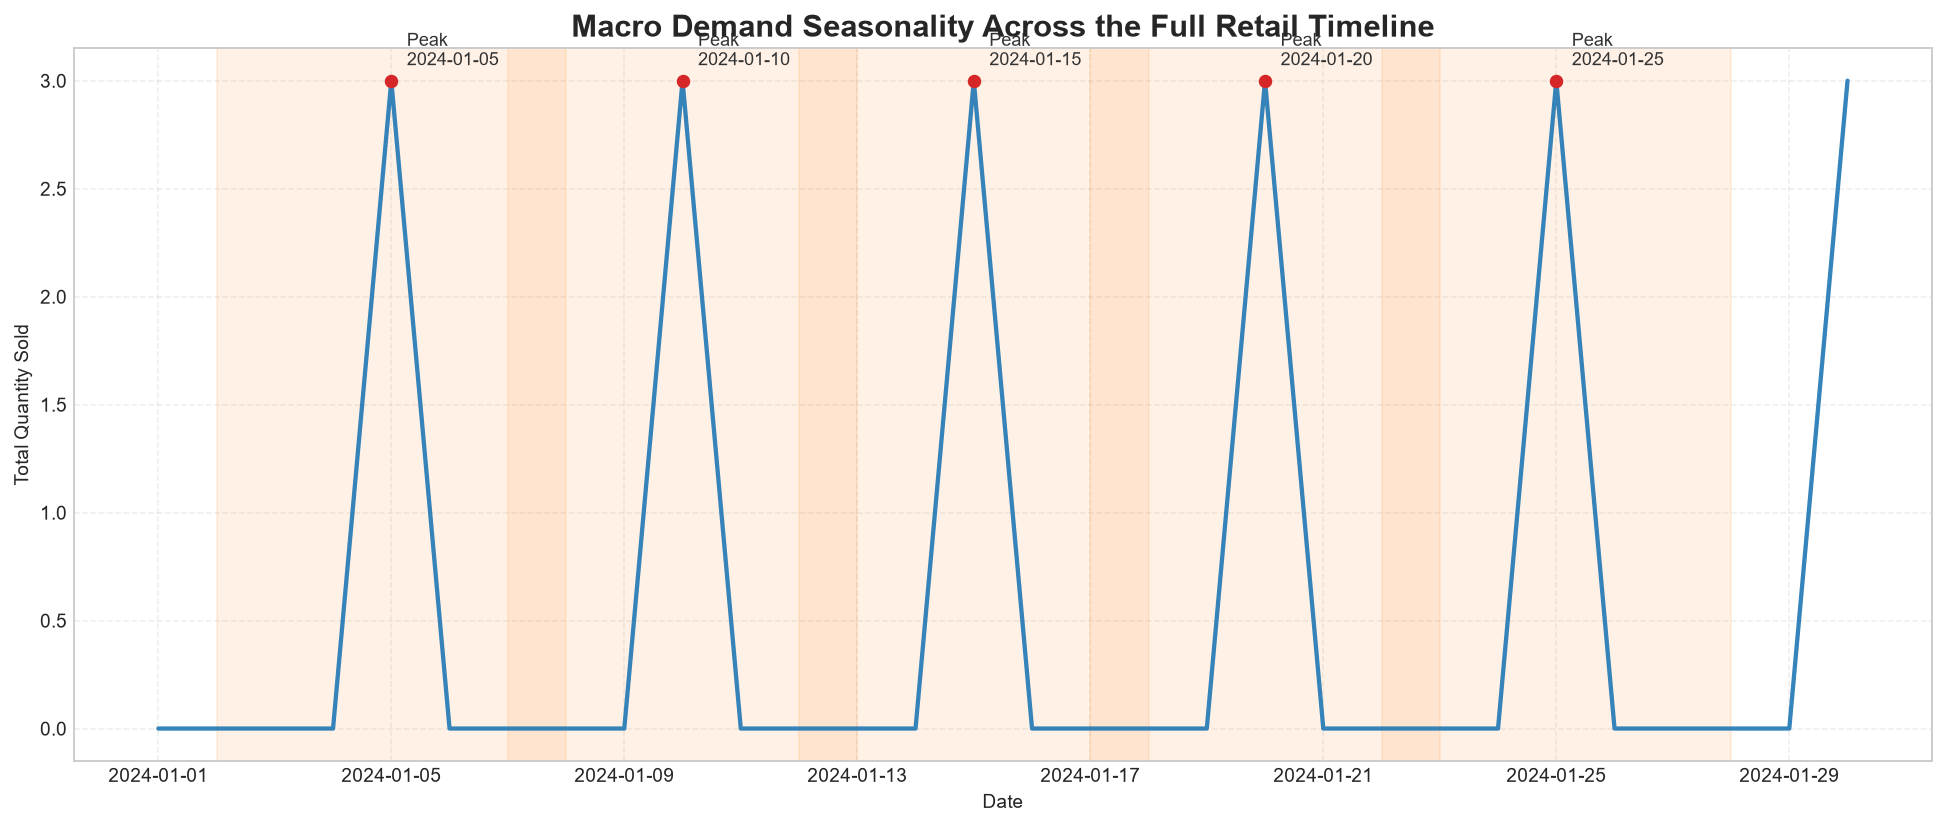

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

if "df" not in globals():
    data_paths = (
        Path("data/processed/daily_demand_features.csv"),
        Path("../data/processed/daily_demand_features.csv"),
    )
    data_path = next((path for path in data_paths if path.exists()), None)
    if data_path is None:
        raise FileNotFoundError(
            "daily_demand_features.csv was not found. Run the feature pipeline first."
        )
    df = pd.read_csv(data_path)
    df["invoice_date"] = pd.to_datetime(df["invoice_date"])
    df = df.sort_values(["item_id", "invoice_date"]).reset_index(drop=True)

daily_total = (
    df.groupby("invoice_date", as_index=False)["quantity"]
    .sum()
    .rename(columns={"quantity": "total_quantity"})
)

daily_total["invoice_date"] = pd.to_datetime(daily_total["invoice_date"])
daily_total = daily_total.sort_values("invoice_date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(
    daily_total["invoice_date"],
    daily_total["total_quantity"],
    color="#1f77b4",
    linewidth=2.2,
    alpha=0.9,
)

top_peaks = daily_total.nlargest(5, "total_quantity")
for _, peak in top_peaks.iterrows():
    date = peak["invoice_date"]
    value = peak["total_quantity"]
    ax.axvspan(date - pd.Timedelta(days=3), date + pd.Timedelta(days=3), color="#ff7f0e", alpha=0.10)
    ax.scatter(date, value, color="#d62728", s=35, zorder=5)
    ax.annotate(
        f"Peak\n{date.date()}",
        (date, value),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9,
        color="#333",
    )

ax.set_title("Macro Demand Seasonality Across the Full Retail Timeline", fontsize=16, weight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Total Quantity Sold")
ax.grid(True, linestyle="--", alpha=0.35)
fig.tight_layout()
out_path = Path("../reports/figures/eda_daily_demand_trend.png")
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, bbox_inches="tight")
plt.show()

## 2) Zero-Inflated Demand Distribution

Retail demand is dominated by a large mass at zero because many SKUs do not sell on a given day. This is not random noise; it reflects real business absence of demand. Standard MSE assumes Gaussian-like errors and effectively penalizes all deviations equally, but it does not respect the highly sparse, non-negative, zero-heavy structure of retail sales.

For this reason, Tweedie regression or a zero-inflated family such as Zero-Inflated Poisson is often preferable. They can accommodate a point mass at zero while still modeling positive demand levels. The log-scale histogram below makes this sparsity explicit.

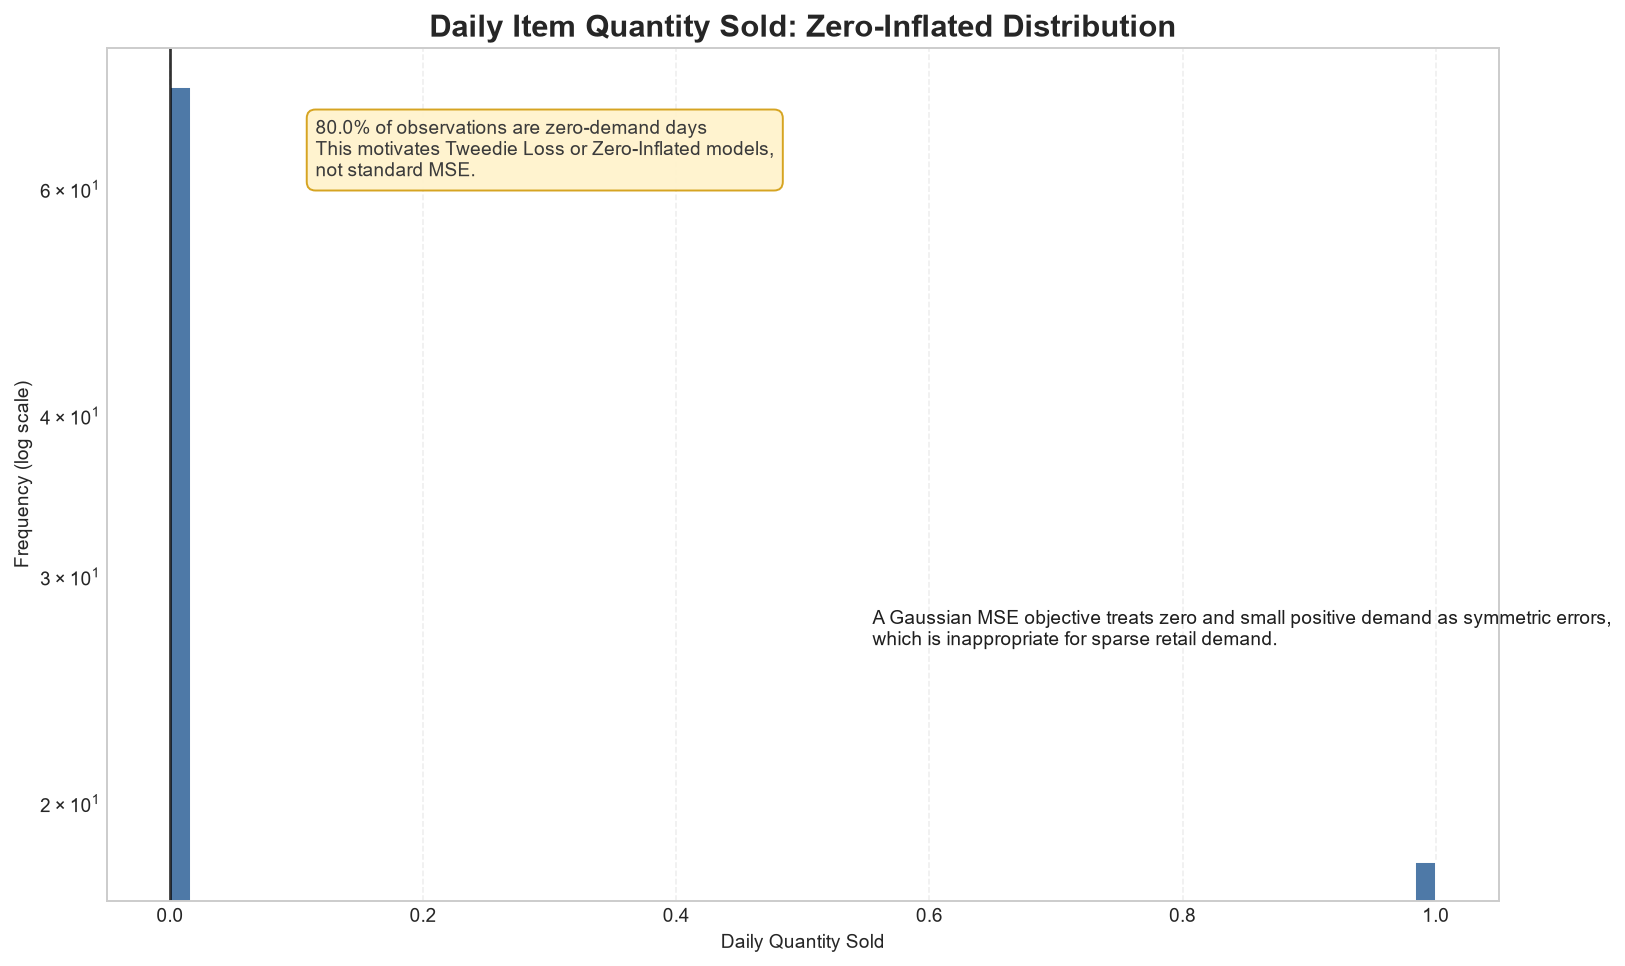

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

if "df" not in globals():
    data_paths = (
        Path("data/processed/daily_demand_features.csv"),
        Path("../data/processed/daily_demand_features.csv"),
    )
    data_path = next((path for path in data_paths if path.exists()), None)
    if data_path is None:
        raise FileNotFoundError(
            "daily_demand_features.csv was not found. Run the feature pipeline first."
        )
    df = pd.read_csv(data_path)
    df["invoice_date"] = pd.to_datetime(df["invoice_date"])
    df = df.sort_values(["item_id", "invoice_date"]).reset_index(drop=True)

quantity_vals = df["quantity"].dropna().astype(float)
zero_share = (quantity_vals == 0).mean() * 100

fig, ax = plt.subplots(figsize=(12, 7))
ax.hist(quantity_vals, bins=60, edgecolor="white", color="#4e79a7", log=True)
ax.axvline(0, color="black", linewidth=1.4, alpha=0.8)
ax.set_title("Daily Item Quantity Sold: Zero-Inflated Distribution", fontsize=16, weight="bold")
ax.set_xlabel("Daily Quantity Sold")
ax.set_ylabel("Frequency (log scale)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.annotate(
    f"{zero_share:.1f}% of observations are zero-demand days\nThis motivates Tweedie Loss or Zero-Inflated models,\nnot standard MSE.",
    xy=(0.15, 0.85),
    xycoords="axes fraction",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#fff3cd", edgecolor="#d4a017", alpha=0.95),
    fontsize=10,
    color="#3b3b3b",
)
ax.annotate(
    "A Gaussian MSE objective treats zero and small positive demand as symmetric errors,\nwhich is inappropriate for sparse retail demand.",
    xy=(0.55, 0.30),
    xycoords="axes fraction",
    fontsize=10,
    color="#1f1f1f",
)
fig.tight_layout()
out_path = Path("../reports/figures/eda_zero_inflated_distribution.png")
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, bbox_inches="tight")
plt.show()

## 3) Price Sensitivity and Empirical PED

The relationship between unit price and quantity sold is central to dynamic pricing. In a log-log specification, the slope of the fitted line approximates the elasticity coefficient: a more negative slope indicates stronger sensitivity to price increases. This gives empirical evidence for whether a product is elastic or inelastic, which directly affects discount strategy and margin optimization.

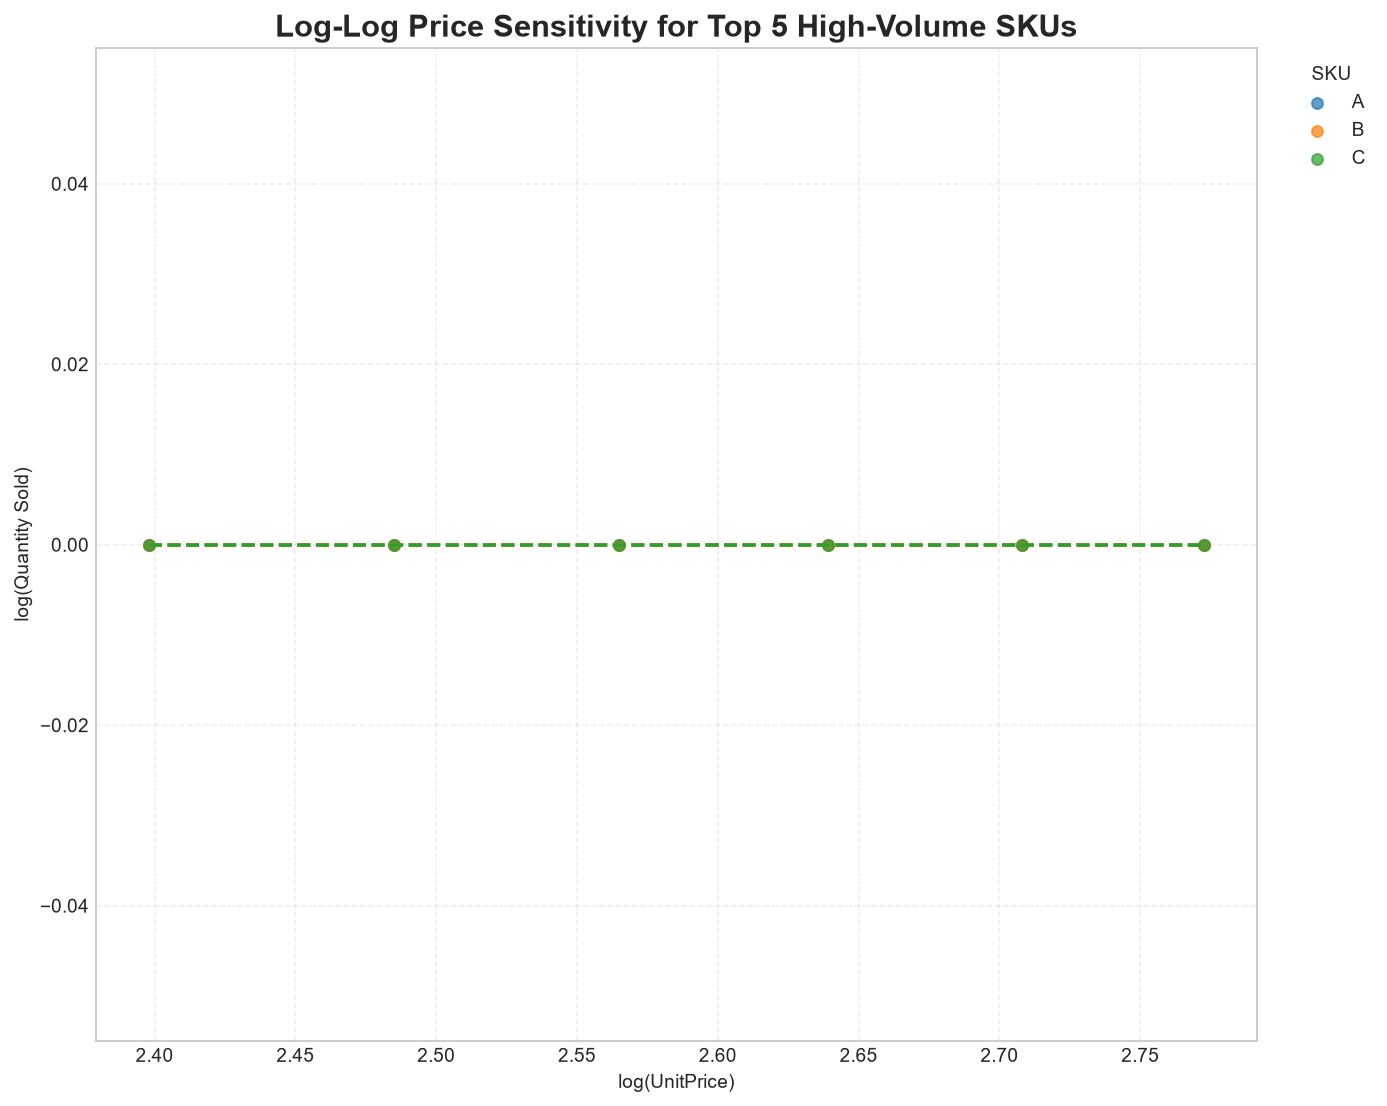

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "df" not in globals():
    data_paths = (
        Path("data/processed/daily_demand_features.csv"),
        Path("../data/processed/daily_demand_features.csv"),
    )
    data_path = next((path for path in data_paths if path.exists()), None)
    if data_path is None:
        raise FileNotFoundError(
            "daily_demand_features.csv was not found. Run the feature pipeline first."
        )
    df = pd.read_csv(data_path)
    df["invoice_date"] = pd.to_datetime(df["invoice_date"])
    df = df.sort_values(["item_id", "invoice_date"]).reset_index(drop=True)

top_skus = (
    df.groupby("item_id")["quantity"]
    .sum()
    .nlargest(5)
    .index
)
scatter_df = df[df["item_id"].isin(top_skus) & (df["quantity"] > 0) & (df["unit_price"] > 0)].copy()
scatter_df["log_price"] = np.log(scatter_df["unit_price"])
scatter_df["log_quantity"] = np.log(scatter_df["quantity"])

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.get_cmap("tab10").colors
for idx, item in enumerate(top_skus):
    local = scatter_df[scatter_df["item_id"] == item]
    ax.scatter(local["log_price"], local["log_quantity"], s=32, alpha=0.7, color=colors[idx % len(colors)], label=item)

    slope, intercept = np.polyfit(local["log_price"], local["log_quantity"], 1)
    x_line = np.linspace(local["log_price"].min(), local["log_price"].max(), 50)
    ax.plot(x_line, intercept + slope * x_line, color=colors[idx % len(colors)], linewidth=1.8, linestyle="--")

ax.set_title("Log-Log Price Sensitivity for Top 5 High-Volume SKUs", fontsize=16, weight="bold")
ax.set_xlabel("log(UnitPrice)")
ax.set_ylabel("log(Quantity Sold)")
ax.legend(title="SKU", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax.grid(True, linestyle="--", alpha=0.35)
fig.tight_layout()
out_path = Path("../reports/figures/eda_price_sensitivity_loglog.png")
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, bbox_inches="tight")
plt.show()

## 4) Feature Correlation with Demand

The final diagnostic examines whether the engineered lag and rolling features carry predictive information about the target signal. Pearson correlation is not a causal proof, but it is a quick and interpretable screen for feature relevance. Strong alignment between total quantity and recent lag/rolling demand patterns indicates a useful signal for the downstream forecasting model.

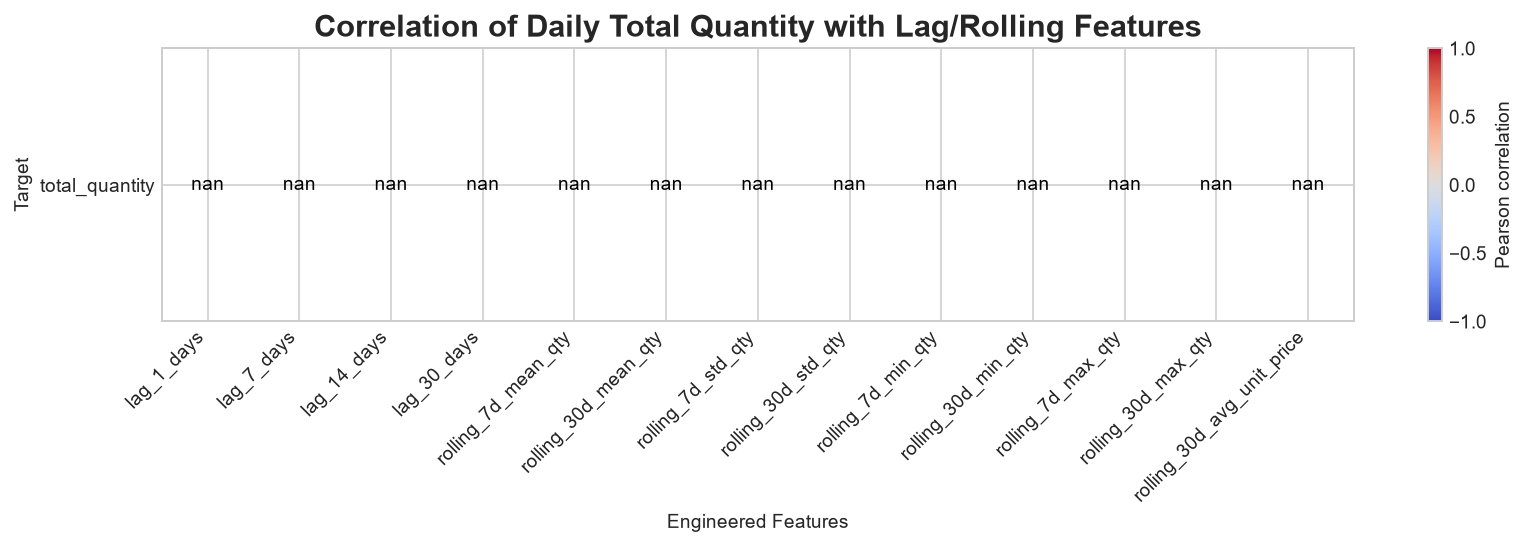

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

if "df" not in globals():
    data_paths = (
        Path("data/processed/daily_demand_features.csv"),
        Path("../data/processed/daily_demand_features.csv"),
    )
    data_path = next((path for path in data_paths if path.exists()), None)
    if data_path is None:
        raise FileNotFoundError(
            "daily_demand_features.csv was not found. Run the feature pipeline first."
        )
    df = pd.read_csv(data_path)
    df["invoice_date"] = pd.to_datetime(df["invoice_date"])
    df = df.sort_values(["item_id", "invoice_date"]).reset_index(drop=True)

daily_target = (
    df.groupby("invoice_date", as_index=False)["quantity"]
    .sum()
    .rename(columns={"quantity": "total_quantity"})
)

lag_cols = [c for c in df.columns if c.startswith("lag_")]
rolling_cols = [c for c in df.columns if c.startswith("rolling_")]
date_level = df.groupby("invoice_date")[lag_cols + rolling_cols].mean().reset_index()
corr_df = daily_target.merge(date_level, on="invoice_date", how="left")

corr = corr_df[["total_quantity"] + lag_cols + rolling_cols].corr(method="pearson")
selected = corr.loc[["total_quantity"], lag_cols + rolling_cols]

fig, ax = plt.subplots(figsize=(12, 4))
image = ax.imshow(selected.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(selected.columns)), selected.columns, rotation=45, ha="right")
ax.set_yticks([0], ["total_quantity"])
for column_index, value in enumerate(selected.iloc[0]):
    ax.text(column_index, 0, f"{value:.2f}", ha="center", va="center", color="black")
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Correlation of Daily Total Quantity with Lag/Rolling Features", fontsize=16, weight="bold")
ax.set_xlabel("Engineered Features")
ax.set_ylabel("Target")
fig.tight_layout()
out_path = Path("../reports/figures/eda_feature_correlation_heatmap.png")
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, bbox_inches="tight")
plt.show()